# ESPRI 实验数据：质子能量的神经网络重建

**功能**：读取 `Ex5sigma.root/tree`，施加角度、Backtracking Z 5σ、Phi12 及回溯成功标志筛选，
按左右臂加载各自的已训练模型，预测质子顶点动能，并与原 `protonEnergy` 作同事件的二维能角及激发能谱对照。

**方法**：uproot/awkward 读取标量和定长数组 → NumPy 筛选 → CPU float64 完整模型推理 →
反归一化到 MeV。实验 `espriSide=1` 对应模拟 arm 0 / Left 模型；`espriSide=0` 对应 arm 1 / Right 模型。
输入严格为 `[naiEnergy, rdcX[espriSide], rdcY[espriSide], NaIBarID]`，对应训练 `[ENaI,RDCX,RDCY,NaIBarID]`。
实验局部棒号 `espriNaiBarId=0..6` 转为 `NaIBarID=7*(1-espriSide)+espriNaiBarId+1`：
Left/side 1 为 1–7，Right/side 0 为 8–14；按 RDCY 从高到低编号，实验棒序保持不变。
对应模拟预处理的 Left=7-localID（原始棒序反转）、Right=8+localID（原序）。
RDC 读出原值直接输入，不再平移、翻转或缩放到另一个坐标约定。

**注意事项**：使用保存的完整模型和各自训练集归一化，不训练、不重新拟合归一化，不把原重建能量作为输入。
须先重新训练四输入模型，旧三输入模型不可用于本 Notebook。
`naiEnergy` 以 MeV、RDCX/Y 以 mm、NaIBarID 以无量纲标量输入；预测直接是质子动能，不再次加上 NaI 能量。
实验只使用确认的筛选与有效输入检查，不新增单棒或近似未击穿门。
原 `protonEnergy` 是实验已有重建结果，不是真值；两列比较不能作为模型精度测量。
两列图使用同一批有有效原重建能量和有限 NN 预测的事件，其他已选事件也保留在输出 ROOT 中。
超出训练集单列范围的事件只标记、不剔除；单列范围内也不保证符合联合训练分布。
运动学沿用 `PictureForThesis/Draw_8.C` 的 **150 MeV/u** 和 `Ex=0、3.368、6.179、10.15 MeV`。
固定输出目录 `ForExperiment_output/`，运行会覆盖同名产物，不修改实验输入或模型文件。

实现参考：`nndl-practice/pytorch/nndl/runner.py` 的 eval/no_grad 推理模式、
本项目的保存模型接口，以及用户指定的 `Draw_8.C` 运动学接口；无需导入参考训练代码。

## 1. 导入与配置

使用已有的 `nn` 环境或具有 torch、uproot、awkward、numpy、matplotlib 的 Python 内核。
绘图阶段通过独立 ROOT 进程调用 `ForExperimentKinematics.C`，Python 内核不需要 PyROOT。

In [1]:
# 功能：用 ENaI、RDCX、RDCY、NaIBarID 四输入的左右臂模型重建实验质子动能，绘制能角图和合并激发能谱。
# 方法：CPU float64、训练集归一化、固定实验 cut；二维图按 0.1° × 0.1 MeV 分箱，横轴显示 50–80°（事件筛选仍为 55–70°），纵轴 0–180 MeV，彩虹对数色标；现有 C++ 接口生成运动学曲线。
# 注意事项：实验 NaIBarID=7*(1-espriSide)+espriNaiBarId+1；须重新训练四输入模型；左右臂映射不可颠倒；原 protonEnergy 仅用于对照；激发能调用现有缺失质量接口、束流为 150 MeV/u；运行覆盖固定目录同名结果。
from pathlib import Path
import hashlib
import json
import shutil
import subprocess
import awkward as ak
import numpy as np
import torch
import uproot
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

PROJECT_DIR = Path("/Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy")
INPUT_FILE = PROJECT_DIR / "Ex5sigma.root"
TREE_NAME = "tree"
MODEL_DIR = PROJECT_DIR / "EspriEnergy_output"
OUTPUT_DIR = PROJECT_DIR / "ForExperiment_output"
KINEMATICS_MACRO = PROJECT_DIR / "ForExperimentKinematics.C"
ROOT_EXECUTABLE = shutil.which("root") or "/opt/homebrew/bin/root"

# 每一项同时约定实验 side、模拟 arm 和模型文件，避免把两套编号直接当作相同编号。
ARM_CONFIG = {
    "Left": {"experiment_side": 1, "simulation_arm": 0, "model": MODEL_DIR / "EspriEnergy_Left.pt"},
    "Right": {"experiment_side": 0, "simulation_arm": 1, "model": MODEL_DIR / "EspriEnergy_Right.pt"},
}
FEATURE_NAMES = ["ENaI", "RDCX", "RDCY", "NaIBarID"]
FEATURE_UNITS = ["MeV", "mm", "mm", "1"]
DTYPE = torch.float64
device = torch.device("cpu")
torch.set_default_dtype(DTYPE)
INVALID_VALUE = -999.0
PREDICT_BATCH_SIZE = 4096

THETA_MIN_DEG, THETA_MAX_DEG = 55.0, 70.0
BACKTRACKING_Z_MEAN_MM = -4.205798
BACKTRACKING_Z_SIGMA_MM = 15.635715
BACKTRACKING_NSIGMA = 5.0
PHI12_CENTER_DEG, PHI12_HALF_WIDTH_DEG = 180.0, 15.0
# 绘图角度范围独立于上方事件筛选范围。
PLOT_THETA_MIN_DEG, PLOT_THETA_MAX_DEG = 50.0, 80.0
THETA_BIN_WIDTH_DEG = 0.1
ENERGY_MIN_MEV, ENERGY_MAX_MEV = 0.0, 180.0
ENERGY_BIN_WIDTH_MEV = 0.1
FRAME_ASPECT_RATIO = 4.0 / 3.0
COLOR_MAP = "rainbow"
plt.rcParams.update({"font.size": 11, "axes.linewidth": 1.0})

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Input:", INPUT_FILE.resolve())
print("Output:", OUTPUT_DIR)
print("Device:", device, "dtype:", DTYPE)
for arm, config in ARM_CONFIG.items():
    print(f"{arm}: exp side={config['experiment_side']} -> sim arm={config['simulation_arm']} -> {config['model'].name}")


Input: /Users/yemingxin/RIKEN_Inelastic_Be/ppBe10/BackTracking/BackAllTracking/Ex5sigma.root
Output: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ForExperiment_output
Device: cpu dtype: torch.float64
Left: exp side=1 -> sim arm=0 -> EspriEnergy_Left.pt
Right: exp side=0 -> sim arm=1 -> EspriEnergy_Right.pt


## 2. 读取实验分支并选择对应臂的 RDC 坐标

角度继续使用实验 `protonTheta`。同一次读取保证 NaI 能量、所选棒号、RDC、原重建能量及 cut 变量保持事件对齐。
NaIBarID 为 1–14 的全局编号，来自 espriNaiBarId 与实验 side，不根据 RDC 位置猜测棒号。
`SourceEntry` 仅表示当前实验树的零起始行号。

In [2]:
branches = [
    "espriSide", "naiEnergy", "rdcX", "rdcY", "protonTheta", "protonEnergy",
    "BacktrackingOK_BDCRDC", "BacktrackingZ_BDCRDC", "phi12", "espriNaiBarId",
]
resolved_input = INPUT_FILE.resolve()
input_stat = resolved_input.stat()
with uproot.open(resolved_input) as root_file:
    tree = root_file[TREE_NAME]
    missing = [name for name in branches if name not in tree.keys()]
    if missing:
        raise KeyError(f"实验树缺少所需分支：{missing}")
    entry_count = tree.num_entries
    arrays = tree.arrays(branches, library="ak", how=dict)

columns = {name: np.asarray(ak.to_numpy(arrays[name])) for name in branches}
for name in branches:
    expected_shape = (entry_count, 2) if name in ("rdcX", "rdcY") else (entry_count,)
    if columns[name].shape != expected_shape:
        raise ValueError(f"{name} shape={columns[name].shape}，预期 {expected_shape}")
side = columns["espriSide"].astype(np.int32)
valid_side = (side == 0) | (side == 1)
# 先替换无效 side 的索引，避免筛选之前发生数组越界；对应事件随后由 valid_side 排除。
side_index = np.where(valid_side, side, 0).astype(np.int64)
row_index = np.arange(entry_count, dtype=np.int64)
ENaI = np.asarray(columns["naiEnergy"], dtype=np.float64)
RDCX = np.asarray(columns["rdcX"][row_index, side_index], dtype=np.float64)
RDCY = np.asarray(columns["rdcY"][row_index, side_index], dtype=np.float64)
theta = np.asarray(columns["protonTheta"], dtype=np.float64)
original_energy = np.asarray(columns["protonEnergy"], dtype=np.float64)
backtracking_z = np.asarray(columns["BacktrackingZ_BDCRDC"], dtype=np.float64)
phi12 = np.asarray(columns["phi12"], dtype=np.float64)
local_bar_id = np.asarray(columns["espriNaiBarId"], dtype=np.int32)
valid_bar_id = (local_bar_id >= 0) & (local_bar_id <= 6)
# 实验 side 与模拟 arm 互补；实验局部棒号为 0--6，模拟 Left 的反序已在预处理完成。
NaIBarID = np.full(entry_count, int(INVALID_VALUE), dtype=np.int32)
valid_bar_rows = valid_side & valid_bar_id
NaIBarID[valid_bar_rows] = 7 * (1 - side[valid_bar_rows]) + local_bar_id[valid_bar_rows] + 1
X_all = np.column_stack((ENaI, RDCX, RDCY, NaIBarID)).astype(np.float64)
print("实验树事件数：", entry_count)
print("实验输入 shape：", X_all.shape)


实验树事件数： 496964
实验输入 shape： (496964, 4)


## 3. 明确施加实验 cut

- 输入有效：side 为 0/1，局部 NaI 棒号为 0–6（转换为 NaIBarID 1–14），NaI 能量有限且为正，所选侧 RDC 坐标有限且大于 −900 mm（沿用实验无效值约定）。
- `55≤protonTheta≤70°`，包含端点。
- `BacktrackingOK_BDCRDC==1`，且 `|BacktrackingZ_BDCRDC+4.205798|≤5×15.635715 mm`。
- `|phi12−180°|<15°`。

逐步统计全样本和两臂计数。原 `protonEnergy` 的有效性不影响这一筛选，只在两列同事件对照时使用。

In [3]:
cutflow = []

def record_cut(name, mask):
    counts = {"stage": name, "all": int(mask.sum())}
    for arm, config in ARM_CONFIG.items():
        counts[arm] = int((mask & (side == config["experiment_side"])).sum())
    cutflow.append(counts)
    print(f"{name:24s}: all={counts['all']}, Left={counts['Left']}, Right={counts['Right']}")

selected = np.ones(entry_count, dtype=bool)
record_cut("input", selected)
selected &= valid_side
record_cut("valid arm", selected)
selected &= valid_bar_id & np.isfinite(X_all).all(axis=1) & (ENaI > 0.0) & (RDCX > -900.0) & (RDCY > -900.0)
record_cut("valid NN inputs", selected)
selected &= np.isfinite(theta) & (theta >= THETA_MIN_DEG) & (theta <= THETA_MAX_DEG)
record_cut("55 <= theta <= 70", selected)
selected &= columns["BacktrackingOK_BDCRDC"] == 1
record_cut("BacktrackingOK == 1", selected)
selected &= np.isfinite(backtracking_z) & (backtracking_z != INVALID_VALUE)
selected &= np.abs(backtracking_z - BACKTRACKING_Z_MEAN_MM) <= BACKTRACKING_NSIGMA * BACKTRACKING_Z_SIGMA_MM
record_cut("Backtracking Z 5sigma", selected)
selected &= np.isfinite(phi12) & (np.abs(phi12 - PHI12_CENTER_DEG) < PHI12_HALF_WIDTH_DEG)
record_cut("Phi12", selected)
if not selected.any():
    raise ValueError("没有事件通过筛选，请检查上方逐步计数和输入分支。")


input                   : all=496964, Left=257499, Right=239465
valid arm               : all=496964, Left=257499, Right=239465
valid NN inputs         : all=496964, Left=257499, Right=239465
55 <= theta <= 70       : all=412283, Left=215239, Right=197044
BacktrackingOK == 1     : all=412283, Left=215239, Right=197044
Backtracking Z 5sigma   : all=136693, Left=72215, Right=64478
Phi12                   : all=39860, Left=19957, Right=19903


## 4. 加载左右臂模型并分别推理

加载自己生成且可信的完整 `.pt`，不重新构建网络。各自使用保存的训练集均值、标准差；
原 `protonEnergy` 不进入模型。输出反归一化后直接为质子动能。
模型范围外的输入只标记，不进行裁剪或额外剔除。

In [4]:
def to_tensor(array):
    return torch.from_numpy(np.ascontiguousarray(array, dtype=np.float64)).to(
        device=device, dtype=DTYPE
    )

results = {}
model_records = {}
for arm, config in ARM_CONFIG.items():
    checkpoint_path = config["model"]
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f"缺少 {arm} 模型：{checkpoint_path}")
    saved = torch.load(checkpoint_path, map_location=device, weights_only=False)
    if saved["arm"] != arm or list(saved["feature_names"]) != FEATURE_NAMES:
        raise ValueError(f"{arm} 模型的臂或输入顺序不匹配。")
    if list(saved["feature_units"]) != FEATURE_UNITS or saved["target_name"] != "ETrue" or saved["target_unit"] != "MeV":
        raise ValueError(f"{arm} 模型输入单位或质子动能目标定义不匹配。")
    x_mean, x_std = np.asarray(saved["x_mean"]), np.asarray(saved["x_std"])
    y_mean, y_std = np.asarray(saved["y_mean"]), np.asarray(saved["y_std"])
    if x_mean.shape != (len(FEATURE_NAMES),) or x_std.shape != (len(FEATURE_NAMES),) or y_mean.size != 1 or y_std.size != 1:
        raise ValueError(f"{arm} 归一化参数维度不匹配。")
    if not all(np.isfinite(value).all() for value in (x_mean, x_std, y_mean, y_std)) or np.any(x_std <= 0) or np.any(y_std <= 0):
        raise ValueError(f"{arm} 归一化参数无效。")
    model = saved["model"].to(device=device, dtype=DTYPE)
    model.eval()
    rows = np.flatnonzero(selected & (side == config["experiment_side"]))
    X = X_all[rows]
    prediction = np.full(len(rows), INVALID_VALUE, dtype=np.float64)
    prediction_ok = np.zeros(len(rows), dtype=np.int8)
    for first in range(0, len(rows), PREDICT_BATCH_SIZE):
        stop = min(first + PREDICT_BATCH_SIZE, len(rows))
        X_n = (X[first:stop] - x_mean) / x_std
        with torch.no_grad():
            prediction_n = model(to_tensor(X_n)).cpu().numpy()
        if prediction_n.shape != (stop - first, 1):
            raise ValueError(f"{arm} 模型输出应为 (batch,1)，实际为 {prediction_n.shape}")
        values = (prediction_n * y_std + y_mean).reshape(-1)
        finite = np.isfinite(values)
        prediction[first:stop] = np.where(finite, values, INVALID_VALUE)
        prediction_ok[first:stop] = finite.astype(np.int8)
    original = original_energy[rows]
    original_ok = np.isfinite(original) & (original > 0.0)
    comparison_ok = original_ok & prediction_ok.astype(bool)
    difference = np.full(len(rows), INVALID_VALUE, dtype=np.float64)
    difference[comparison_ok] = prediction[comparison_ok] - original[comparison_ok]
    outside = ((X < saved["train_feature_min"]) | (X > saved["train_feature_max"]))
    results[arm] = {
        "SourceEntry": rows, "espriSide": side[rows],
        "SimulationArm": np.full(len(rows), config["simulation_arm"], dtype=np.int32),
        "ENaI": X[:, 0], "RDCX": X[:, 1], "RDCY": X[:, 2], "NaIBarID": X[:, 3].astype(np.int32),
        "protonTheta": theta[rows], "protonEnergy": original,
        "ProtonEnergyNN": prediction, "DeltaProtonEnergyNN": difference,
        "PredictionOK": prediction_ok, "OriginalEnergyOK": original_ok.astype(np.int8),
        "ComparisonOK": comparison_ok.astype(np.int8), "OutsideTrainingRange": outside.any(axis=1).astype(np.int8),
        "espriNaiBarId": columns["espriNaiBarId"][rows].astype(np.int32),
        "BacktrackingOK_BDCRDC": columns["BacktrackingOK_BDCRDC"][rows].astype(np.int32),
        "BacktrackingZ_BDCRDC": backtracking_z[rows], "phi12": phi12[rows],
    }
    model_records[arm] = {
        "checkpoint": str(checkpoint_path.resolve()),
        "sha256": hashlib.sha256(checkpoint_path.read_bytes()).hexdigest(),
        "experiment_side": config["experiment_side"], "simulation_arm": config["simulation_arm"],
        "epoch": int(saved["epoch"]), "configuration": saved["configuration"],
        "x_mean": x_mean.tolist(), "x_std": x_std.tolist(), "y_mean": y_mean.tolist(), "y_std": y_std.tolist(),
        "selected_events": int(len(rows)), "finite_predictions": int(prediction_ok.sum()),
        "nonpositive_predictions": int(((prediction <= 0.0) & prediction_ok.astype(bool)).sum()),
        "same_event_comparison": int(comparison_ok.sum()),
        "outside_training_range": int(outside.any(axis=1).sum()),
        "outside_by_feature": {name: int(count) for name, count in zip(FEATURE_NAMES, outside.sum(axis=0))},
    }
    print(f"{arm}: selected={len(rows)}, NN valid={prediction_ok.sum()}, common comparison={comparison_ok.sum()}")
    print("  outside training range:", model_records[arm]["outside_by_feature"])


Left: selected=19957, NN valid=19957, common comparison=19957
  outside training range: {'ENaI': 0, 'RDCX': 3, 'RDCY': 1, 'NaIBarID': 0}
Right: selected=19903, NN valid=19903, common comparison=19903
  outside training range: {'ENaI': 0, 'RDCX': 1, 'RDCY': 4, 'NaIBarID': 0}


## 5. 保存两臂预测与筛选记录

每个 ROOT 文件的 `tree` 保留通过实验 cut 的全部事件和原树行号；非有限预测写 −999、PredictionOK=0。
`ComparisonOK` 标记用于两列同事件对照的样本。`DeltaProtonEnergyNN` 是 NN 减原重建的能量差，不是对真值的误差。

In [5]:
for arm, columns_out in results.items():
    output_path = OUTPUT_DIR / f"Predicted_{arm}.root"
    with uproot.recreate(output_path) as root_file:
        output_tree = root_file.mktree("tree", {name: value.dtype for name, value in columns_out.items()})
        output_tree.extend(columns_out)
    print("Saved:", output_path)

summary = {
    "input_file": str(resolved_input), "tree_name": TREE_NAME, "input_entries": int(entry_count),
    "input_size_bytes": int(input_stat.st_size), "input_mtime_ns": int(input_stat.st_mtime_ns),
    "feature_mapping": {"ENaI": "naiEnergy", "RDCX": "rdcX[espriSide]", "RDCY": "rdcY[espriSide]",
                        "NaIBarID": "7*(1-espriSide)+espriNaiBarId+1"},
    "cuts": {
        "protonTheta_deg": [THETA_MIN_DEG, THETA_MAX_DEG], "theta_endpoints_included": True,
        "BacktrackingOK_BDCRDC": 1, "BacktrackingZ_mean_mm": BACKTRACKING_Z_MEAN_MM,
        "BacktrackingZ_sigma_mm": BACKTRACKING_Z_SIGMA_MM, "BacktrackingZ_nsigma": BACKTRACKING_NSIGMA,
        "phi12_center_deg": PHI12_CENTER_DEG, "phi12_half_width_deg": PHI12_HALF_WIDTH_DEG,
        "phi12_strict_inequality": True,
    },
    "cutflow": cutflow, "models": model_records,
    "comparison_definition": "Same selected events with finite NN prediction and finite positive original protonEnergy; original reconstruction is not truth.",
}
(OUTPUT_DIR / "ExperimentSummary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
print("Saved:", OUTPUT_DIR / "ExperimentSummary.json")


Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ForExperiment_output/Predicted_Left.root
Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ForExperiment_output/Predicted_Right.root
Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ForExperiment_output/ExperimentSummary.json


## 6. 按 Draw_8.C 生成运动学曲线

下个单元格调用 ROOT 辅助宏，质量来自 `NuclearMass::Get("10Be")` 与 `Get("1H")`。
曲线为 150 MeV/u 的 `Ex=0、3.368、6.179、10.15 MeV`，依次为参考宏的红、蓝、绿、品红，
实线、线宽1、透明度0.4；保留现有接口返回的两条运动学分支。
曲线及参数另存 CSV/JSON；不在 Python 中手写核质量或运动学公式。

In [6]:
if not KINEMATICS_MACRO.is_file():
    raise FileNotFoundError(f"缺少运动学辅助宏：{KINEMATICS_MACRO}")
if not Path(ROOT_EXECUTABLE).is_file():
    raise FileNotFoundError("未找到 ROOT 可执行文件，请修改配置中的 ROOT_EXECUTABLE。")
command = [str(ROOT_EXECUTABLE), "-l", "-b", "-q", str(KINEMATICS_MACRO)]
completed = subprocess.run(command, cwd=PROJECT_DIR, text=True, capture_output=True)
print(completed.stdout)
if completed.stderr:
    print(completed.stderr)
completed.check_returncode()
curve_path = OUTPUT_DIR / "KinematicsCurves.csv"
kinematics_configuration = json.loads((OUTPUT_DIR / "KinematicsConfiguration.json").read_text())
curve_points = np.atleast_1d(np.genfromtxt(curve_path, delimiter=",", names=True))
if len(curve_points) == 0 or len(curve_points) != kinematics_configuration["points"]:
    raise ValueError("运动学曲线点数与导出参数不一致。")
if not np.isfinite(curve_points["Theta_deg"]).all() or not np.isfinite(curve_points["ProtonEnergy_MeV"]).all():
    raise ValueError("运动学曲线含非有限值。")
curves = []
for state in np.unique(curve_points["StateIndex"]):
    state_points = curve_points[curve_points["StateIndex"] == state]
    for branch in np.unique(state_points["CurveBranch"]):
        points = state_points[state_points["CurveBranch"] == branch]
        points = np.sort(points, order="PointIndex")
        curves.append({
            "excitation": float(points["Ex_MeV"][0]), "branch": int(branch),
            "theta": points["Theta_deg"], "energy": points["ProtonEnergy_MeV"],
            "color": tuple(float(points[name][0]) for name in ("Red", "Green", "Blue")),
        })
print("Kinematics:", kinematics_configuration["beam_energy_per_u_MeV"], "MeV/u; Ex=", kinematics_configuration["excitation_MeV"])


add include path : /Users/yemingxin/anaroot/src/install/include
reading libXMLParser.so
reading libananadeko.dylib
reading libanacore.dylib
reading libanabrips.dylib
reading libanadali.dylib
reading libanasamurai.dylib
reading libanacatana.dylib
reading libanaespri.dylib
reading libanawinds.dylib
reading libanasilicons.dylib
reading libanatogaxsi.dylib
reading libanaloop.dylib
reading libanaloopexample.dylib
reading libanaloopencexample.dylib
Processing /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ForExperimentKinematics.C...
Kinematics: 150 MeV/u, Ex=0/3.368/6.179/10.15 MeV; points=71576; output=/Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ForExperiment_output

Kinematics: 150 MeV/u; Ex= [0.0, 3.368, 6.179, 10.15]


## 7. 同事件的质子动能—角度二维图与运动学叠加

三行依次为 Left、Right、左右臂合并（Left + Right）；左列为原 `protonEnergy`，右列为 `ProtonEnergyNN`。
合并图逐 bin 相加两臂的原始计数，不取平均；各臂仍使用相同的 `ComparisonOK` 样本。
横轴显示角度 50–80°、bin 宽0.1°；事件角度筛选仍为 55–70°。动能 0–180 MeV、bin 宽0.1 MeV。
六图保持原始计数，使用共同彩虹（rainbow）对数色标，绘图区均为4:3；曲线只作理论位置对照。
显示范围外的事件计数会报告，不用显示范围重新筛选或修改预测。

Left Original {'visible_events': 19957, 'outside_display': 0}
Left NN {'visible_events': 19957, 'outside_display': 0}
Right Original {'visible_events': 19903, 'outside_display': 0}
Right NN {'visible_events': 19903, 'outside_display': 0}
Combined Original {'visible_events': 39860, 'outside_display': 0}
Combined NN {'visible_events': 39860, 'outside_display': 0}


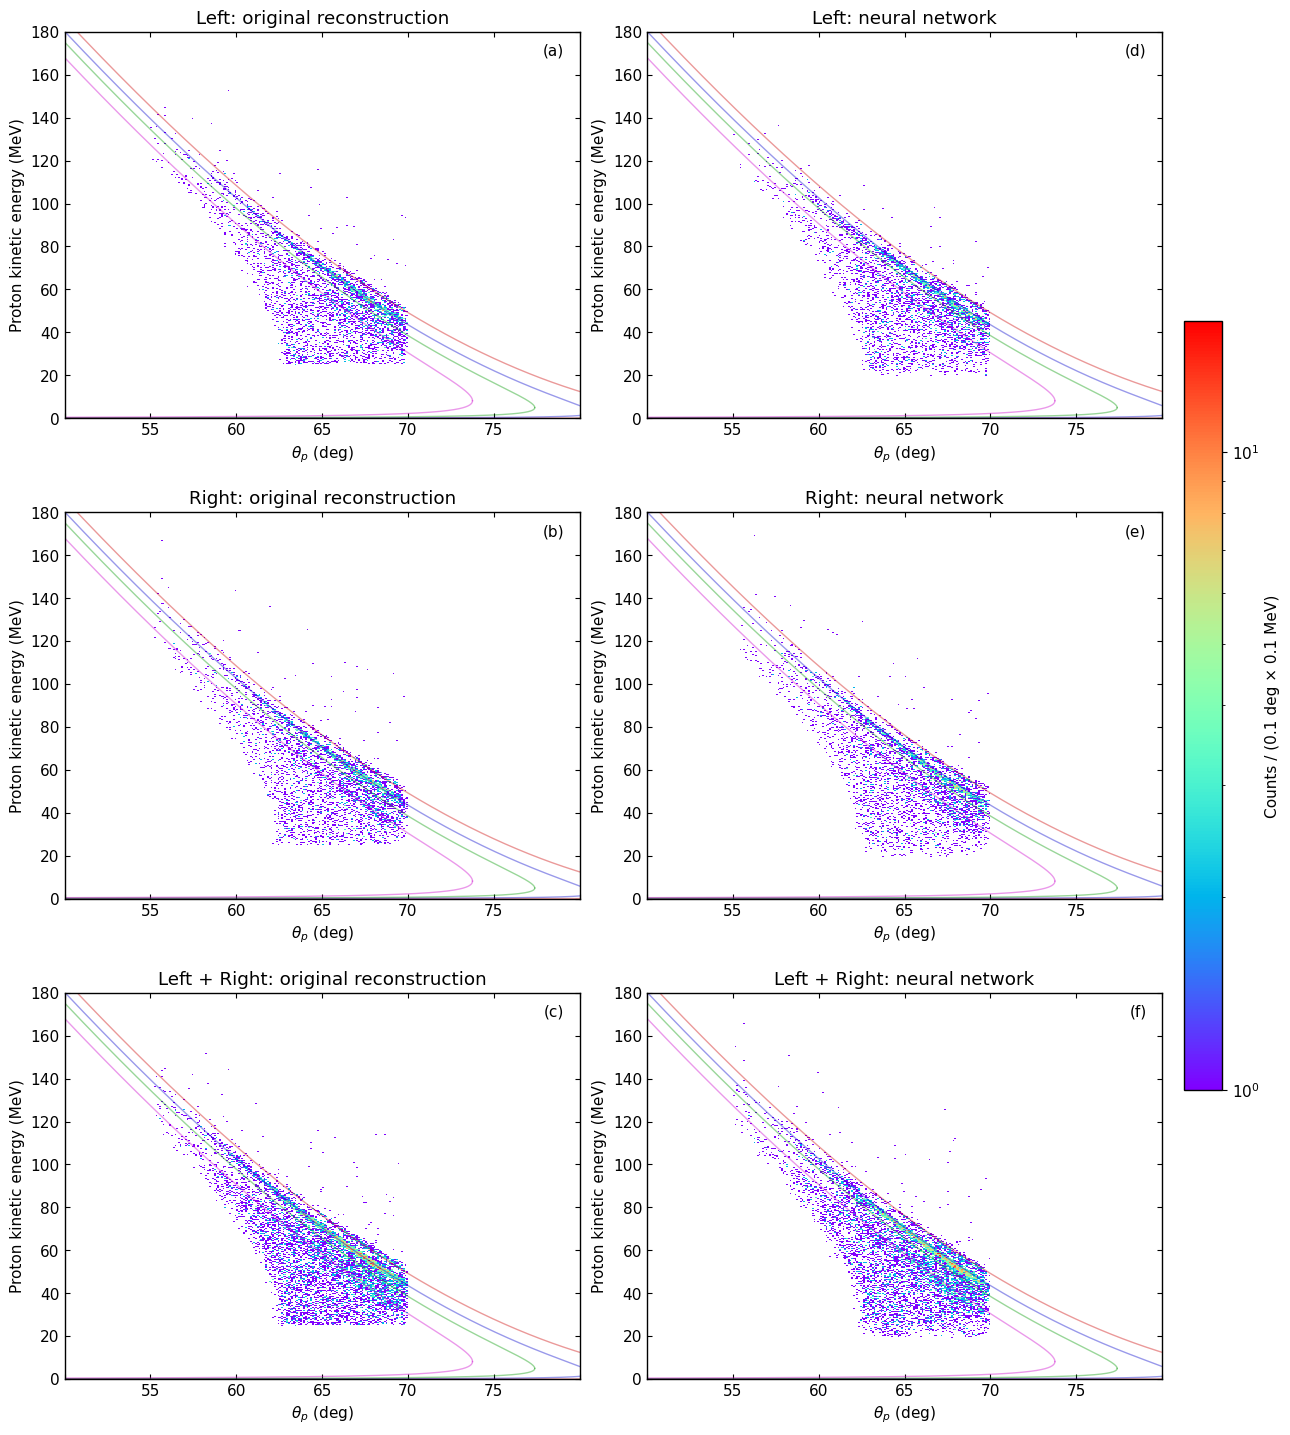

Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ForExperiment_output/ProtonEnergyAngleComparison.pdf


In [7]:
angle_edges = np.linspace(PLOT_THETA_MIN_DEG, PLOT_THETA_MAX_DEG,
                          int(round((PLOT_THETA_MAX_DEG - PLOT_THETA_MIN_DEG) / THETA_BIN_WIDTH_DEG)) + 1)
energy_edges = np.linspace(ENERGY_MIN_MEV, ENERGY_MAX_MEV,
                           int(round((ENERGY_MAX_MEV - ENERGY_MIN_MEV) / ENERGY_BIN_WIDTH_MEV)) + 1)
histograms = {}
plot_counts = {}
for arm in ("Left", "Right"):
    result = results[arm]
    common = result["ComparisonOK"].astype(bool)
    plot_counts[arm] = {"common_events": int(common.sum())}
    for label, branch in [("Original", "protonEnergy"), ("NN", "ProtonEnergyNN")]:
        histogram, _, _ = np.histogram2d(result["protonTheta"][common], result[branch][common],
                                         bins=(angle_edges, energy_edges))
        histograms[f"{arm}_{label}"] = histogram
        plot_counts[arm][label] = {
            "visible_events": int(histogram.sum()),
            "outside_display": int(common.sum() - histogram.sum()),
        }
        print(arm, label, plot_counts[arm][label])

# 两臂事件互斥且共用分箱；逐 bin 相加得到合并样本，保留原始计数。
plot_counts["Combined"] = {
    "common_events": sum(plot_counts[arm]["common_events"] for arm in ("Left", "Right"))
}
for label in ("Original", "NN"):
    histograms[f"Combined_{label}"] = histograms[f"Left_{label}"] + histograms[f"Right_{label}"]
    plot_counts["Combined"][label] = {
        key: sum(plot_counts[arm][label][key] for arm in ("Left", "Right"))
        for key in ("visible_events", "outside_display")
    }
    print("Combined", label, plot_counts["Combined"][label])

maximum = max(2.0, max(histogram.max() for histogram in histograms.values()))
normalization = LogNorm(vmin=1.0, vmax=maximum)
color_map = plt.get_cmap(COLOR_MAP).copy()
color_map.set_bad("white")
fig, axes = plt.subplots(3, 2, figsize=(12.8, 14.4), layout="constrained")
for row, arm in enumerate(("Left", "Right", "Combined")):
    for column, label in enumerate(("Original", "NN")):
        ax = axes[row, column]
        histogram = histograms[f"{arm}_{label}"]
        mesh = ax.pcolormesh(angle_edges, energy_edges, np.ma.masked_less_equal(histogram.T, 0),
                             cmap=color_map, norm=normalization, shading="flat", rasterized=True)
        for curve in curves:
            ax.plot(curve["theta"], curve["energy"], color=curve["color"],
                    alpha=kinematics_configuration["line_alpha"], linewidth=1, linestyle="-")
        ax.set(xlim=(PLOT_THETA_MIN_DEG, PLOT_THETA_MAX_DEG), ylim=(ENERGY_MIN_MEV, ENERGY_MAX_MEV),
               xlabel=r"$\theta_p$ (deg)", ylabel="Proton kinetic energy (MeV)")
        method = "original reconstruction" if label == "Original" else "neural network"
        arm_title = "Left + Right" if arm == "Combined" else arm
        ax.set_title(f"{arm_title}: {method}")
        ax.set_box_aspect(1.0 / FRAME_ASPECT_RATIO)
        ax.grid(False)
        ax.tick_params(direction="in", top=True, right=True)
        panel_label = chr(ord("a") + 3 * column + row)
        ax.text(0.97, 0.97, f"({panel_label})", transform=ax.transAxes, ha="right", va="top")
fig.colorbar(mesh, ax=axes.ravel().tolist(), fraction=0.035, pad=0.02,
             label=f"Counts / ({THETA_BIN_WIDTH_DEG:g} deg × {ENERGY_BIN_WIDTH_MEV:g} MeV)")
fig.canvas.draw()
for ax in axes.flat:
    lower, upper = ax.get_xlim()
    visible_labels = [tick.label1 for tick in ax.xaxis.get_major_ticks()
                      if lower <= tick.get_loc() <= upper and tick.label1.get_visible()]
    if len(visible_labels) > 1:
        visible_labels[0].set_visible(False)
        visible_labels[-1].set_visible(False)
pdf_path = OUTPUT_DIR / "ProtonEnergyAngleComparison.pdf"
fig.savefig(pdf_path, dpi=200, bbox_inches="tight", pad_inches=0.06)
fig.savefig(OUTPUT_DIR / "ProtonEnergyAngleComparison.png", dpi=180, bbox_inches="tight", pad_inches=0.06)
plt.show()
plt.close(fig)
np.savez(OUTPUT_DIR / "EnergyAngleHistograms.npz", angle_edges=angle_edges, energy_edges=energy_edges, **histograms)
plot_summary = {
    "counts": plot_counts, "theta_range_deg": [PLOT_THETA_MIN_DEG, PLOT_THETA_MAX_DEG],
    "energy_range_MeV": [ENERGY_MIN_MEV, ENERGY_MAX_MEV],
    "theta_bin_deg": THETA_BIN_WIDTH_DEG, "energy_bin_MeV": ENERGY_BIN_WIDTH_MEV,
    "shared_color_scale": {"vmin": 1.0, "vmax": float(maximum), "scale": "log", "normalization": "raw counts"},
    "kinematics": kinematics_configuration,
}
(OUTPUT_DIR / "PlotSummary.json").write_text(json.dumps(plot_summary, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
print("Saved:", pdf_path)


Original {'visible_events': 39801, 'underflow': 59, 'overflow': 0}
NN {'visible_events': 39807, 'underflow': 53, 'overflow': 0}
Input pairs=39860, valid pairs=39860, invalid original=0, invalid NN=0


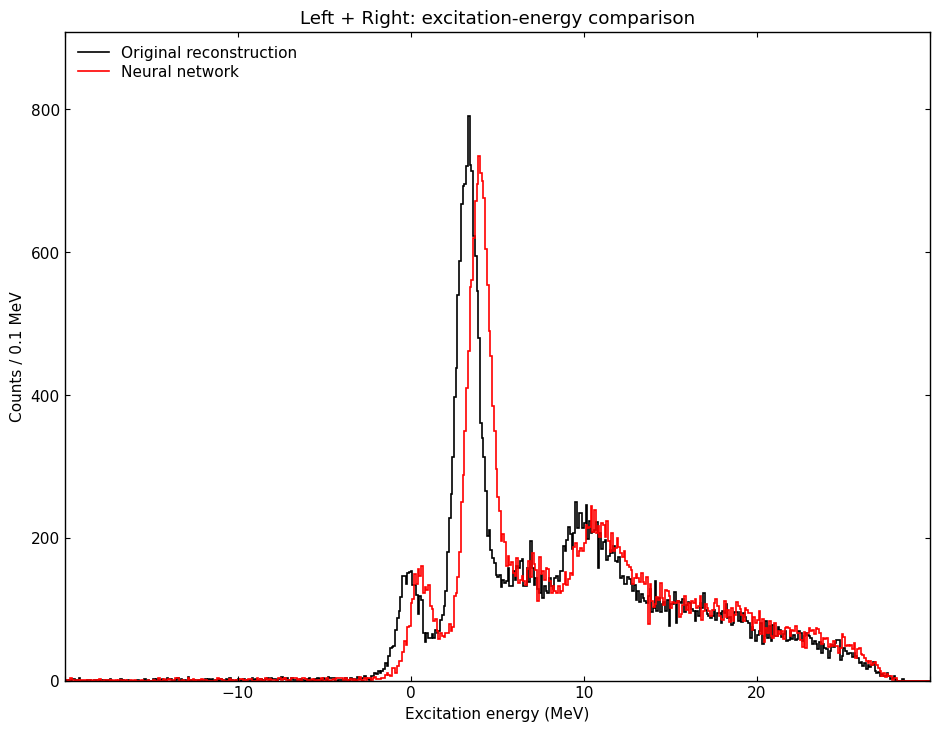

Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ForExperiment_output/ExcitationEnergyComparison.pdf


In [8]:
# 功能：合并左右臂，以原重建和 NN 质子动能分别计算激发能，叠加黑、红不透明轮廓的 ROOT 风格阶梯式直方图（不填充，线宽 1.2）。
# 方法：同一 ComparisonOK 样本、同一 protonTheta、150 MeV/u；ROOT 调用现有缺失质量接口。
# 注意事项：先运行前面的模型推理和运动学单元格；角度 deg、动能/激发能 MeV；
# 两种激发能均有效的同事件用于对照，不按二维图显示范围裁剪；原重建不是真值。
# 核质量从 NuclearMass 查询；不训练模型；运行会覆盖本单元格同名输出。
from tempfile import TemporaryDirectory

EX_MIN_MEV, EX_MAX_MEV, EX_BIN_WIDTH_MEV = -20.0, 30.0, 0.1
ex_edges = np.linspace(EX_MIN_MEV, EX_MAX_MEV,
                       int(round((EX_MAX_MEV - EX_MIN_MEV) / EX_BIN_WIDTH_MEV)) + 1)
ex_inputs = []
ex_source_entries, ex_sides = [], []
for arm in ("Left", "Right"):
    arm_result = results[arm]
    common = arm_result["ComparisonOK"].astype(bool)
    ex_inputs.append(np.column_stack((arm_result["protonTheta"][common],
                                      arm_result["protonEnergy"][common],
                                      arm_result["ProtonEnergyNN"][common])))
    ex_source_entries.append(arm_result["SourceEntry"][common])
    ex_sides.append(arm_result["espriSide"][common])
ex_inputs = np.concatenate(ex_inputs, axis=0)
ex_source_entries = np.concatenate(ex_source_entries)
ex_sides = np.concatenate(ex_sides)
if len(ex_inputs) == 0:
    raise ValueError("没有同事件对照样本可用于激发能重建。")
# 与上方理论曲线一致；缺失质量接口要求总束流动能，10Be 的整数质量数为 10。
ex_beam_total_mev = 10.0 * float(kinematics_configuration["beam_energy_per_u_MeV"])
ex_macro_source = r"""// 功能：逐事件计算两组质子动能对应的 10Be 激发能，导出数值及有效标志。
// 方法：NuclearMass 的 MassAMU（u）质量、TwoBodyKinematicsMissingMass、cos(theta)。
// 注意事项：束流总动能 MeV，靶质子静止；失败值 -999 配合有效标志，保留输入行序。
#include "/Users/yemingxin/anaroot/output/Analysis/MyToolsFunction/TwoBodyKinematics/TwoBodyKinematics.h"
#include "/Users/yemingxin/anaroot/output/Analysis/MyToolsFunction/TwoBodyKinematics/TwoBodyKinematics.cc"
#include "/Users/yemingxin/anaroot/output/Analysis/MyToolsFunction/NuclearMass/NuclearMass.h"
#include "/Users/yemingxin/anaroot/output/Analysis/MyToolsFunction/NuclearMass/NuclearMass.cc"
#include "TMath.h"
#include <cmath>
#include <fstream>
#include <iomanip>
#include <stdexcept>
void ForExperimentExcitation() {
    const Double_t kInvalidValue = -999.0;
    const Double_t massBe = NuclearMass::Get("10Be").MassMeV;
    const Double_t massBeAmu = NuclearMass::Get("10Be").MassAMU;
    const Double_t massPAmu = NuclearMass::Get("1H").MassAMU;
    const Double_t beamEnergy = __BEAM_TOTAL_MEV__;
    std::ifstream input("ExcitationInputs.txt");
    std::ofstream output("ExcitationValues.csv");
    if (!input || !output) throw std::runtime_error("Cannot open excitation input/output");
    output << "ExOriginal_MeV,ExNN_MeV,OriginalOK,NNOK\n" << std::setprecision(17);
    Double_t theta = 0.0, originalEnergy = 0.0, nnEnergy = 0.0;
    while (input >> theta >> originalEnergy >> nnEnergy) {
        const Double_t energies[2] = {originalEnergy, nnEnergy};
        Double_t excitation[2] = {kInvalidValue, kInvalidValue};
        Int_t valid[2] = {0, 0};
        for (Int_t method = 0; method < 2; ++method) {
            if (!std::isfinite(theta) || theta < 0.0 || theta > 180.0
                || !std::isfinite(energies[method]) || energies[method] <= 0.0
                || massBe + beamEnergy - energies[method] <= 0.0) continue;
            const Double_t value = TwoBodyKinematicsMissingMass(
                massBeAmu, massPAmu, massPAmu, massBeAmu, beamEnergy, energies[method],
                std::cos(theta * TMath::DegToRad()));
            if (std::isfinite(value)) {
                excitation[method] = value;
                valid[method] = 1;
            }
        }
        output << excitation[0] << ',' << excitation[1] << ','
               << valid[0] << ',' << valid[1] << '\n';
    }
    output.close();
    if (!input.eof() || !output) throw std::runtime_error("Excitation data transfer failed");
}
""".replace("__BEAM_TOTAL_MEV__", format(ex_beam_total_mev, ".17g"))
# 独立 ROOT 进程沿用已有 C++ 接口；临时文件在读取结果后自动清理，无需 PyROOT。
with TemporaryDirectory(prefix="for_experiment_excitation_") as ex_temp:
    ex_temp_path = Path(ex_temp)
    np.savetxt(ex_temp_path / "ExcitationInputs.txt", ex_inputs, fmt="%.17g")
    ex_macro = ex_temp_path / "ForExperimentExcitation.C"
    ex_macro.write_text(ex_macro_source, encoding="utf-8")
    ex_run = subprocess.run([str(ROOT_EXECUTABLE), "-l", "-b", "-q", str(ex_macro)],
                            cwd=ex_temp_path, text=True, capture_output=True)
    if ex_run.returncode:
        print(ex_run.stdout)
        print(ex_run.stderr)
    ex_run.check_returncode()
    ex_values = np.atleast_1d(np.genfromtxt(ex_temp_path / "ExcitationValues.csv",
                                           delimiter=",", names=True))
if len(ex_values) != len(ex_inputs):
    raise ValueError("激发能输出行数与输入不一致，不能保证事件对齐。")
ex_original_ok = ex_values["OriginalOK"].astype(bool)
ex_nn_ok = ex_values["NNOK"].astype(bool)
ex_pair_ok = ex_original_ok & ex_nn_ok
ex_histograms, ex_statistics = {}, {}
for method, branch in (("Original", "ExOriginal_MeV"), ("NN", "ExNN_MeV")):
    values = ex_values[branch][ex_pair_ok]
    ex_histograms[method], _ = np.histogram(values, bins=ex_edges)
    ex_statistics[method] = {
        "visible_events": int(ex_histograms[method].sum()),
        "underflow": int((values < EX_MIN_MEV).sum()),
        "overflow": int((values > EX_MAX_MEV).sum()),
    }
    print(method, ex_statistics[method])
print(f"Input pairs={len(ex_inputs)}, valid pairs={ex_pair_ok.sum()}, "
      f"invalid original={(~ex_original_ok).sum()}, invalid NN={(~ex_nn_ok).sum()}")

ex_fig, ex_ax = plt.subplots(figsize=(9.6, 7.2), layout="constrained")
for method, color, label in (("Original", "#000000", "Original reconstruction"),
                              ("NN", "#FF0000", "Neural network")):
    ex_ax.stairs(ex_histograms[method], ex_edges, fill=False, baseline=0.0,
                 color=color, linewidth=1.2, alpha=1.0, label=label)
ex_ax.set(xlim=(EX_MIN_MEV, EX_MAX_MEV),
          ylim=(0.0, max(1.0, 1.15 * max(h.max() for h in ex_histograms.values()))),
          xlabel="Excitation energy (MeV)",
          ylabel=f"Counts / {ex_edges[1] - ex_edges[0]:g} MeV",
          title="Left + Right: excitation-energy comparison")
ex_ax.set_box_aspect(1.0 / FRAME_ASPECT_RATIO)
ex_ax.tick_params(direction="in", top=True, right=True)
ex_ax.legend(loc="upper left", frameon=False, labelspacing=0.25)
ex_fig.canvas.draw()
ex_tick_labels = [tick.label1 for tick in ex_ax.xaxis.get_major_ticks()
                  if EX_MIN_MEV <= tick.get_loc() <= EX_MAX_MEV and tick.label1.get_visible()]
if len(ex_tick_labels) > 1:
    ex_tick_labels[0].set_visible(False)
    ex_tick_labels[-1].set_visible(False)
for suffix in ("pdf", "png"):
    ex_fig.savefig(OUTPUT_DIR / f"ExcitationEnergyComparison.{suffix}", dpi=200,
                   bbox_inches="tight", pad_inches=0.06)
plt.show()
plt.close(ex_fig)
np.savez(OUTPUT_DIR / "ExcitationEnergyComparison.npz", edges_MeV=ex_edges,
         Original=ex_histograms["Original"], NN=ex_histograms["NN"],
         SourceEntry=ex_source_entries, espriSide=ex_sides,
         ExOriginal_MeV=ex_values["ExOriginal_MeV"], ExNN_MeV=ex_values["ExNN_MeV"],
         OriginalOK=ex_original_ok, NNOK=ex_nn_ok, PairOK=ex_pair_ok)
ex_summary = {
    "reaction": "10Be(p,p)10Be", "beam_energy_total_MeV": ex_beam_total_mev,
    "theta_selection_deg": [THETA_MIN_DEG, THETA_MAX_DEG],
    "range_MeV": [EX_MIN_MEV, EX_MAX_MEV], "bin_width_MeV": EX_BIN_WIDTH_MEV,
    "input_pairs": int(len(ex_inputs)), "valid_pairs": int(ex_pair_ok.sum()),
    "invalid_original": int((~ex_original_ok).sum()), "invalid_NN": int((~ex_nn_ok).sum()),
    "normalization": "raw counts, same events with both missing-mass reconstructions valid",
    "counts": ex_statistics,
}
(OUTPUT_DIR / "ExcitationEnergySummary.json").write_text(
    json.dumps(ex_summary, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
print("Saved:", OUTPUT_DIR / "ExcitationEnergyComparison.pdf")


## 输出

- `Predicted_Left.root`、`Predicted_Right.root`：两臂通过 cut 的实验事件、模型预测、原重建和有效性标志；同时保留统一的 NaIBarID 与实验局部 espriNaiBarId。
- `ExperimentSummary.json`：实验来源、逐步 cut 计数、臂映射、模型 SHA256 与训练参数。
- `KinematicsCurves.csv`、`KinematicsConfiguration.json`：现有 C++ 接口生成的运动学曲线及参数。
- `ProtonEnergyAngleComparison.pdf/.png`：三行两列的同事件能角对照图（Left、Right、左右臂合并）。
- `EnergyAngleHistograms.npz`、`PlotSummary.json`：六图原始计数（含 Combined_Original、Combined_NN）、分箱与可见事件统计，供以后仅重画。

- `ExcitationEnergyComparison.pdf/.png`：左右臂合并的原重建/NN 激发能叠加阶梯式直方图（无填充）（−20–30 MeV，bin 宽0.1 MeV）。
- `ExcitationEnergyComparison.npz`、`ExcitationEnergySummary.json`：同事件激发能、有效标志、直方图及范围外计数。

从上到下运行。本 Notebook 的模型应用结果需要结合实验 NaI 标定和数据/模拟响应进一步检查；
原重建结果与运动学曲线均不作为模型训练标签或实验真值。